In [1]:
import numpy as np
import pandas as pd
import sklearn
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.ensemble import BaggingRegressor, GradientBoostingRegressor, StackingRegressor, RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

# Exploratory Data Analysis

Read the data

In [33]:
hour_df = pd.read_csv("data/hour.csv")

In [34]:
hour_df

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61


In [35]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


target variable is ``cnt``

In [36]:
y = hour_df['cnt']

Drop unnecessary columns

In [37]:
hour_df = hour_df.drop(columns=['instant', 'dteday', 'casual', 'registered'])

One hot encode the categorical features

In [38]:
X, y = hour_df.drop(columns=['cnt']), hour_df['cnt']

In [39]:
categorical_cols = ['season', 'weathersit', 'mnth', 'hr']

In [40]:
# Create the transformer for the categorical data
one_hot_transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Create the ColumnTransformer to apply the encoding only to the categorical columns
# 'remainder='passthrough'' ensures that your numerical columns are kept unchanged.
preprocessor = ColumnTransformer(
    transformers=[
        ('onehot', one_hot_transformer, categorical_cols)
    ],
    remainder='passthrough'  # Pass through all other columns (your numerical data)
)

In [41]:
X = X[categorical_cols]
hour_train_onehot_arr = preprocessor.fit_transform(X)
feature_names = preprocessor.get_feature_names_out()
X = pd.DataFrame(hour_train_onehot_arr, columns=feature_names)
print(hour_df.head())

   season  yr  mnth  hr  holiday  weekday  workingday  weathersit  temp  \
0       1   0     1   0        0        6           0           1  0.24   
1       1   0     1   1        0        6           0           1  0.22   
2       1   0     1   2        0        6           0           1  0.22   
3       1   0     1   3        0        6           0           1  0.24   
4       1   0     1   4        0        6           0           1  0.24   

    atemp   hum  windspeed  cnt  
0  0.2879  0.81        0.0   16  
1  0.2727  0.80        0.0   40  
2  0.2727  0.80        0.0   32  
3  0.2879  0.75        0.0   13  
4  0.2879  0.75        0.0    1  


Train and test split

In [42]:
hour_train_X, hour_test_X, y_train, y_test = train_test_split(X, y, train_size=0.8)

In [43]:
hour_train_X.shape, hour_test_X.shape

((13903, 44), (3476, 44))

# Theoretical Background

if we have y = f(x) + \epsilon , D = {(x_i, y_i)} and we need to find \hat{f(x; D)} such that \hat{f} = argmin_{f} (y - \hat{f(x;D)})^2 then:

![Formula](form1.svg)

## Bias

Bias is the inability of the model to predict beyond a certain assumption. It is the consistent error of the model predictions from the actual observations. Higher the bias, the lower the model is fit for the data, leading to underfitting. Very low bias leads to Overfitting.

![Bias](bias.svg)

## Variance

Variance is the ability of the model to generalize beyond the data it was trained on. High variance indicates memorization or overfitting where the model has fit the data too well, while low variance indicates the model has not captured the relations between data enough.

![Variance](variance.svg)

## Bias - vs - Variance

We wish to have low bias and low variance, but these operate on two different directions. High bias indicates low variance and vice versa. Given a data, we assume that it is noisy. We do not want a model that models the noise as well, only the actual values. 

We can do dimensionality or feature reduction, or use ensemble learning

![BVV](Bias_and_variance_contributing_to_total_error.svg.png)

# Machinery

In [44]:
def baseline_model(train_X, train_y, test_X, test_y, model):
    model.fit(train_X, train_y)
    pred = model.predict(test_X)
    err = root_mean_squared_error(test_y, pred)
    return model, err

# Experiments

## Baseline

### Decision Tree Regressor

In [45]:
dt_reg = DecisionTreeRegressor(max_depth=6)

In [46]:
hour_train_X.shape, hour_test_X.shape

((13903, 44), (3476, 44))

In [47]:
dt_reg, err1 = baseline_model(hour_train_X, y_train, hour_test_X, y_test, dt_reg)

In [48]:
print(err1)

139.4440850580384


### Linear Regression

In [49]:
lin_reg = LinearRegression()

In [50]:
lin_reg, err_lin_reg = baseline_model(hour_train_X, y_train, hour_test_X, y_test, lin_reg)

In [51]:
print(err_lin_reg)

112.1756682237929


Linear Regression is better

## Bagging

Hypothesis: Bagging primarily targets variance reduction.

In Bagging (Bootstrap aggregating), we first generate Bootstrap samples (sampling from the dataset without replacement). We train a model on each bootstrap sample and average their output. We take a bunch of weak learners (accuracy just above 50%) and build a strong learner (accuracy just below 100%)

Benefits:
1. less overfitting
2. Reduces variance as aggregation over weak learners leads to more stable output near the central tendency
3. can be done in parallel

Cons:
1. Doesn't prevent high bias, as if majority have high bias, the output too shifts there (average is sensitive to bias)
2. Computationally expensive than a single model

In [52]:
bag_reg = BaggingRegressor(estimator=dt_reg, n_estimators=50, random_state=0)

In [53]:
bag_reg, err_bag = baseline_model(hour_train_X, y_train, hour_test_X, y_test, bag_reg)

In [54]:
print(err_bag)

137.0025159231535


Random Forest is the Bagging of Decision Trees

In [55]:
randf_reg = RandomForestRegressor(n_estimators=50, max_depth=6)

In [56]:
randf_reg, err_randf = baseline_model(hour_train_X, y_train, hour_test_X, y_test, randf_reg)

In [57]:
print(err_randf)

137.79433178738836


Discuss whether the bagging technique effectively reduced variance compared to the single Decision Tree baseline.

Bagging of Decision Trees has marginally reduced the error

In [58]:
bag_reg1 = BaggingRegressor(estimator=lin_reg, n_estimators=50, random_state=0)
bag_reg1, err_bag1 = baseline_model(hour_train_X, y_train, hour_test_X, y_test, bag_reg1)
print(err_bag1)

112.11844774909025


## Boosting

Hypothesis: Boosting primarily targets bias reduction.

Boosting builds models sequentially, where each model is built to correct the errors made by its predecessors. So each model focuses more on the errorneous points by its predecessor. It does so by increasing the weights on the predictions made on those points in its objective function. Reduces Bias as it iteratively improves on its error on the data, drawing closer to the true value each iteration. We take a bunch of weak learners (accuracy just above 50%) and build a strong learner (accuracy just below 100%)

In [59]:
gboost_reg = GradientBoostingRegressor(random_state=0)

In [60]:
gboost_reg, err_gb = baseline_model(hour_train_X, y_train, hour_test_X, y_test, gboost_reg)

In [61]:
print(err_gb)

109.45771493511637


Discuss whether boosting achieved a better result than both the single model and the bagging ensemble, supporting the idea of bias reduction.

Boosting has significantly reduced the error

## Stacking

Explain the principle of Stacking and how the Meta-Learner learns to combine the predictions of diverse Base Learners optimally. 

Stacking combines the outputs of a bunch of weak learners to train a meta learner who trains on their outputs. Each weak / base learner is valided on the data and a new dataset is created. The number of features of this new dataset is the number of weak learners. The  meta learner then has to predict the true target on these features. This way, the meta learner learns to weigh each weak learner and correct their biases.

In [62]:
knn = KNeighborsRegressor()

In [63]:
rig_reg = Ridge()

In [64]:
stack_reg = StackingRegressor(estimators=[
        ('knn', knn),
        ('bag', bag_reg),
        ('boost', gboost_reg)
    ],
    final_estimator = rig_reg
)

In [66]:
stack_reg, err_st = baseline_model(hour_train_X, y_train, hour_test_X, y_test, stack_reg)

In [67]:
print(err_st)

106.81298473703626


# Results

In [69]:
rmse_results = {
    "dt": err1,
    "lin_reg": err_lin_reg,
    "bag": err_bag,
    "boost": err_gb,
    "stack": err_st
}
rmse_df = pd.Series(rmse_results).to_frame(name='RMSE')

In [70]:
rmse_df

,RMSE
dt,139.444085
lin_reg,112.175668
bag,137.002516
boost,109.457715
stack,106.812985


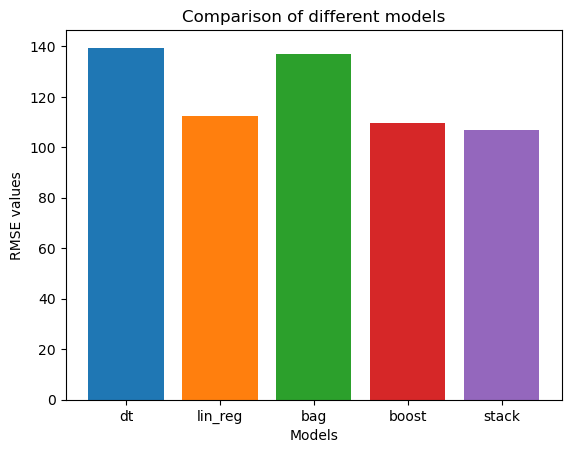

In [72]:
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
plt.bar(
    x=list(rmse_results.keys()),
    height=list(rmse_results.values()),
    color=colors[:len(rmse_results)] # Pass the list of colors, sliced to match the number of bars
)
plt.xlabel("Models")
plt.ylabel("RMSE values")
plt.title("Comparison of different models")
plt.savefig("images/comp.png")
plt.show()

As you can see in the bar chart, the order of performance is:
1. Stacking
2. Boosting
3. Linear Regression
4. Bagging
5. Decision Trees

# Conclusion

The best performing model is the Stacked Regressor

Each model has its own bias-variance tradeoff. The Stacked learner combines each model output and effectively equalizes or average out the differences to give a better result (with low bias and variance). By using different models, it can learn from different kinds of uncorrelated errors and features made and used by the weak learners.